# AI Fundamentals Coding Challenge

**Nama:** SARAH KURNIASIH   
**Tanggal:** 17 OKTOBER 2026
<b>Dataset:</b> Incident Management Process Enriched Event Log 141.712 event dari 24.918 insiden<br>
<b>Link Dataset yang digunakan:</b>
<a href="https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log">Incident Management Process Enriched Event Log</a>
<br>
<b>Sumber data:</b> Amaral, C., Fantinato, M., & Peres, S. (2018).
<i>Incident management process enriched event log</i> [Dataset]. UCI Machine Learning Repository.
<a href="https://doi.org/10.24432/C5754H">https://doi.org/10.24432/C5754H</a> (Lisensi CC BY 4.0)

**Domain:** IT Service Management (ITSM) Incident Management & Service Level Agreement (SLA)

**Tujuan Analisis:** Apakah informasi yang tersedia saat tiket insiden pertama kali dibuka dapat digunakan untuk memprediksi apakah tiket tersebut akan melanggar SLA?

---
## Daftar Isi
1. [Challenge 1 - Data Exploration](#challenge-1)
2. [Challenge 2 - Machine Learning](#challenge-2)
3. [Challenge 3 - Prediction](#challenge-3)
4. [Challenge 4 - Integrasi Gemini API](#challenge-4)
5. [Challenge 5 - Responsible AI Reflection](#challenge-5)

---


Catatan terkait Dataset:
1. Silahkan gunakan dataset yang sesuai dengan ide mini demo day kelompok kamu atau dapat dicari di open source platform lainnya seperti:
  a. https://www.kaggle.com/datasets
  b. https://www.bps.go.id/
  c. https://data.worldbank.org
  d. https://data.cityofchicago.org/
  e. https://djpk.kemenkeu.go.id/portal/data/apbd
  f. https://archive.ics.uci.edu/datasets
  

## Setup Awal
Jalankan cell di bawah ini terlebih dahulu sebelum mengerjakan challenge apa pun.

In [1]:
# Import library dasar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
%matplotlib inline
RANDOM_STATE = 1082026  # gunakan nilai ini di semua fungsi yang membutuhkan random_state

print('Setup berhasil. Library siap digunakan.')

Setup berhasil. Library siap digunakan.


**Unduh Dataset**

In [2]:
# Soal 1.0: Unduh dataset langsung dari UCI
import urllib.request, zipfile, glob

URL = 'https://archive.ics.uci.edu/static/public/498/incident+management+process+enriched+event+log.zip'
urllib.request.urlretrieve(URL, 'incident.zip')

with zipfile.ZipFile('incident.zip') as z:
    z.extractall('incident_data')

# Antisipasi jika di dalam zip masih ada zip lagi
for inner_zip in glob.glob('incident_data/**/*.zip', recursive=True):
    with zipfile.ZipFile(inner_zip) as z:
        z.extractall('incident_data')

csv_files = glob.glob('incident_data/**/*.csv', recursive=True)
print('File CSV ditemukan:', csv_files)

File CSV ditemukan: ['incident_data/incident_event_log.csv']


---
<a id='challenge-1'></a>
## Challenge 1 - Data Exploration (Pandas)

**Tujuan:** Memahami struktur dataset, mendeteksi missing values, dan menampilkan insight awal.

### Instruksi
- Muat dataset ke dalam DataFrame
- Tampilkan 5 baris pertama, info(), dan describe()
- Cek missing values dan duplikasi data
- Buat minimal 2 visualisasi dari pilihan berikut: distribusi fitur, histogram, scatter plot, correlation heatmap, atau box plot
- Tuliskan insight dalam sel markdown berdasarkan pertanyaan yang diberikan

In [3]:

# Di dataset ini, nilai kosong ditulis sebagai '?', jadi diubah menjadi NaN
DATA_PATH = csv_files[0]
df_events = pd.read_csv(DATA_PATH, na_values='?', low_memory=False)

print(f'Dataset shape (event log): {df_events.shape}')
df_events.head()

Dataset shape (event log): (141712, 36)


,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


In [4]:
# Memahami Struktur Event log  Satu insiden = banyak baris (setiap update tiket tercatat)
print('Jumlah baris (event)      :', len(df_events))
print('Jumlah insiden unik       :', df_events['number'].nunique())

print('\nJumlah event per insiden:')
print(df_events['number'].value_counts().describe().round(1))

print('\nContoh perjalanan satu insiden:')
contoh = df_events['number'].iloc[0]
print(df_events.loc[df_events['number'] == contoh,
      ['number', 'incident_state', 'sys_mod_count', 'made_sla',
       'priority', 'assignment_group', 'sys_updated_at']].to_string(index=False))

Jumlah baris (event)      : 141712
Jumlah insiden unik       : 24918

Jumlah event per insiden:
count    24918.0
mean         5.7
std          3.7
min          2.0
25%          3.0
50%          5.0
75%          7.0
max         58.0
Name: count, dtype: float64

Contoh perjalanan satu insiden:
    number incident_state  sys_mod_count  made_sla     priority assignment_group  sys_updated_at
INC0000045            New              0      True 3 - Moderate         Group 56 29/2/2016 01:23
INC0000045       Resolved              2      True 3 - Moderate         Group 56 29/2/2016 08:53
INC0000045       Resolved              3      True 3 - Moderate         Group 56 29/2/2016 11:29
INC0000045         Closed              4      True 3 - Moderate         Group 56  5/3/2016 12:00


In [5]:
# Soal 1.2: Informasi umum dataset (level event)
print('=== Dataset Info ===')
df_events.info()

print('\n=== Dataset Describe (kolom numerik) ===')
print(df_events.describe())

print('\n=== Missing Values (% per kolom, hanya yang > 0) ===')
missing = df_events.isnull().mean().mul(100).round(1).sort_values(ascending=False)
print(missing[missing > 0])

print('\n=== Duplicated Rows ===')
print(f'Total: {df_events.duplicated().sum()}')

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   number                   141712 non-null  object
 1   incident_state           141712 non-null  object
 2   active                   141712 non-null  bool  
 3   reassignment_count       141712 non-null  int64 
 4   reopen_count             141712 non-null  int64 
 5   sys_mod_count            141712 non-null  int64 
 6   made_sla                 141712 non-null  bool  
 7   caller_id                141683 non-null  object
 8   opened_by                136877 non-null  object
 9   opened_at                141712 non-null  object
 10  sys_created_by           88636 non-null   object
 11  sys_created_at           88636 non-null   object
 12  sys_updated_by           141712 non-null  object
 13  sys_updated_at           141712 non-null  object
 14 

In [6]:
# Soal 1.3a: Ubah event log menjadi tabel 1 baris per insiden
df_events = df_events.sort_values(['number', 'sys_mod_count'], kind='stable')

# Fitur yang tersedia saat tiket DIBUKA (bukan informasi dari masa depan)
FITUR_SAAT_DIBUKA = ['contact_type', 'location', 'category', 'subcategory', 'u_symptom',
                     'impact', 'urgency', 'priority', 'assignment_group', 'opened_at']

awal = (df_events.drop_duplicates('number', keep='first')
        .set_index('number')[FITUR_SAAT_DIBUKA])
akhir = (df_events.drop_duplicates('number', keep='last')
         .set_index('number')[['made_sla', 'resolved_at']])
df = awal.join(akhir).reset_index()

# Fitur waktu dari opened_at
opened = pd.to_datetime(df['opened_at'], format='%d/%m/%Y %H:%M', errors='coerce')
resolved = pd.to_datetime(df['resolved_at'], format='%d/%m/%Y %H:%M', errors='coerce')
df['opened_hour'] = opened.dt.hour            # jam tiket dibuka (0-23)
df['opened_dayofweek'] = opened.dt.dayofweek  # hari (0=Senin ... 6=Minggu)

# Durasi HANYA untuk eksplorasi (tidak boleh jadi fitur, karena baru diketahui setelah selesai)
df['durasi_jam_eda'] = (resolved - opened).dt.total_seconds() / 3600

# Target: 1 = SLA terlanggar, 0 = SLA terpenuhi
df['sla_terlanggar'] = (df['made_sla'].astype(str).str.lower() == 'false').astype(int)
df = df.drop(columns=['opened_at', 'resolved_at', 'made_sla'])

print(f'Shape tabel insiden: {df.shape}')
print('Tanggal opened_at gagal dibaca:', opened.isna().sum())
print('\nDistribusi target:')
print(df['sla_terlanggar'].value_counts().rename({0: 'SLA terpenuhi (0)', 1: 'SLA terlanggar (1)'}))
print('\nProporsi (%):')
print((df['sla_terlanggar'].value_counts(normalize=True) * 100).round(1))
df.head()

Shape tabel insiden: (24918, 14)
Tanggal opened_at gagal dibaca: 0

Distribusi target:
sla_terlanggar
SLA terpenuhi (0)     15803
SLA terlanggar (1)     9115
Name: count, dtype: int64

Proporsi (%):
sla_terlanggar
0    63.4
1    36.6
Name: proportion, dtype: float64


,number,contact_type,location,category,subcategory,u_symptom,impact,urgency,priority,assignment_group,opened_hour,opened_dayofweek,durasi_jam_eda,sla_terlanggar
0,INC0000045,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,2 - Medium,2 - Medium,3 - Moderate,Group 56,1,0,10.216667,0
1,INC0000047,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,4,0,29.200000,0
2,INC0000057,Phone,Location 204,Category 20,Subcategory 125,Symptom 471,2 - Medium,2 - Medium,3 - Moderate,Group 70,6,0,20.750000,0
3,INC0000060,Phone,Location 204,Category 9,Subcategory 97,Symptom 450,2 - Medium,2 - Medium,3 - Moderate,Group 25,6,0,53.466667,0
4,INC0000062,Phone,Location 93,Category 53,Subcategory 168,Symptom 232,2 - Medium,2 - Medium,3 - Moderate,Group 70,6,0,8.883333,1


In [7]:
# Soal 1.3b: Sanity check tiket yang melanggar SLA seharusnya lebih lama selesai
print('Median durasi penyelesaian (jam) per status SLA:')
print(df.groupby('sla_terlanggar')['durasi_jam_eda'].median().round(1))

Median durasi penyelesaian (jam) per status SLA:
sla_terlanggar
0      1.1
1    201.4
Name: durasi_jam_eda, dtype: float64


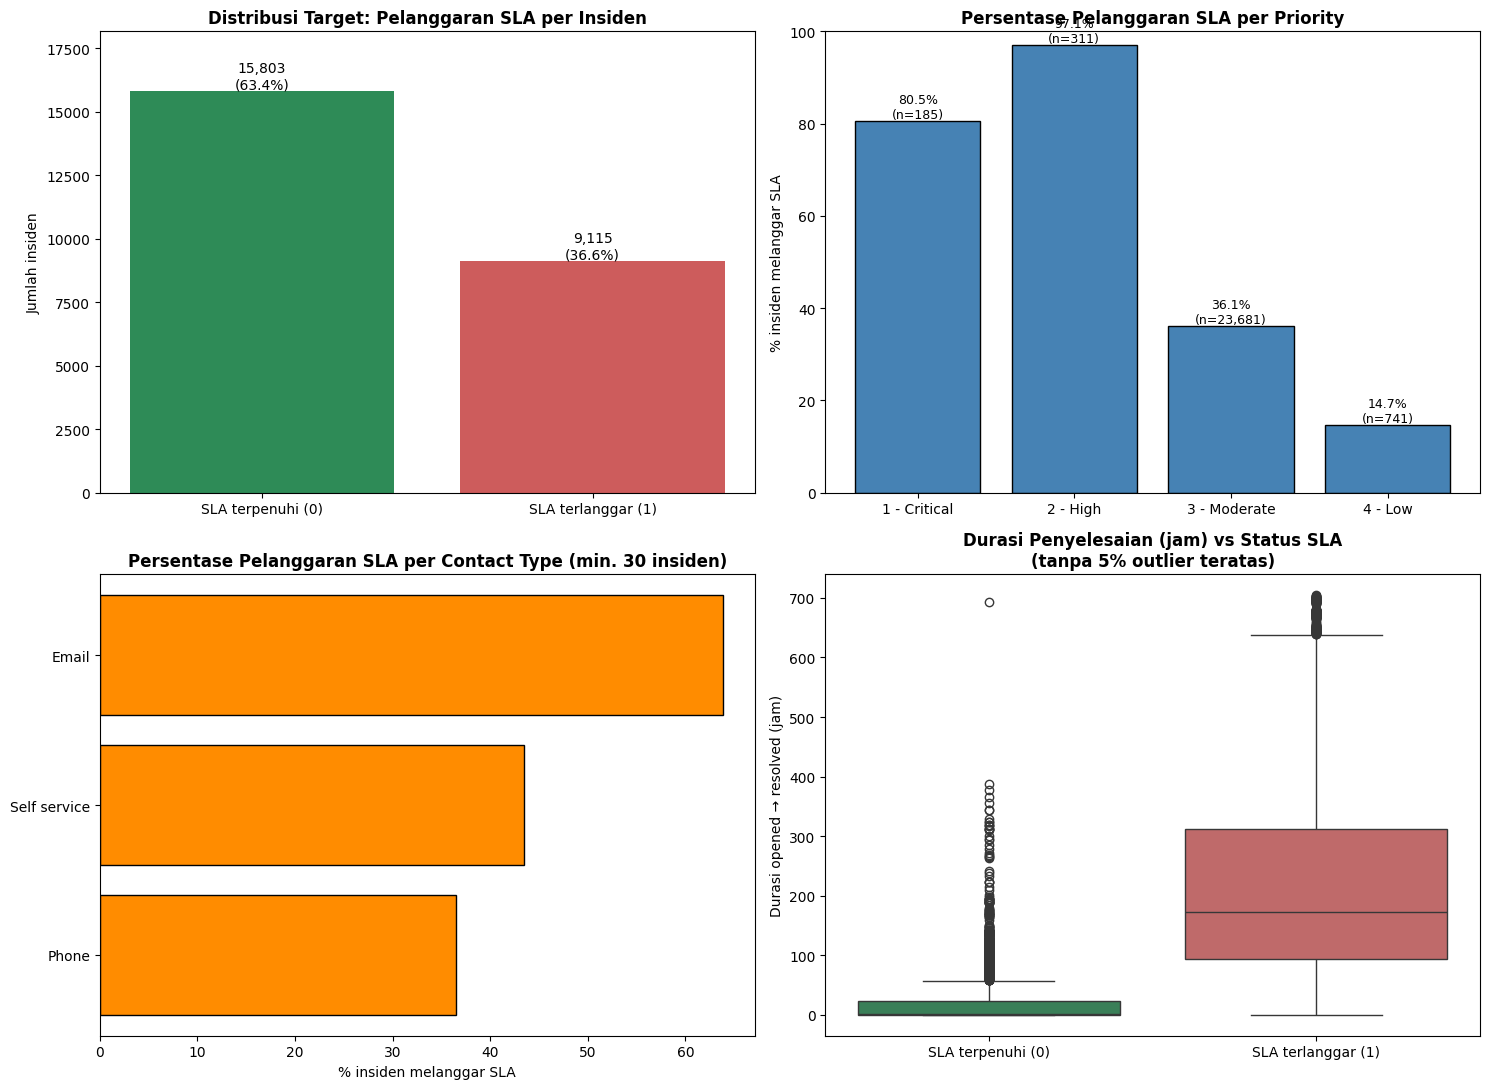

=== Pelanggaran SLA per Priority ===
              jumlah_insiden  persen_terlanggar
priority                                       
1 - Critical             185               80.5
2 - High                 311               97.1
3 - Moderate           23681               36.1
4 - Low                  741               14.7

=== Pelanggaran SLA per Contact Type ===
                jumlah_insiden  persen_terlanggar
contact_type                                     
Phone                    24684               36.5
Self service               161               43.5
Email                       61               63.9
IVR                          9                0.0
Direct opening               3                0.0

=== Missing values di tabel insiden (fitur saat tiket dibuka) ===
location              52
category              39
subcategory           69
u_symptom           5735
assignment_group     906
durasi_jam_eda      1556
dtype: int64


In [8]:
# Soal 1.3: Visualisasi data (minimal 2 grafik)
#
# GUIDE: Pilih 2-3 jenis visualisasi dari berikut:
# 1. Distribution/Histogram
# 2. Scatter plot (relationship antar features)
# 3. Correlation heatmap
# 4. Box plot (per kategori jika ada)
# 5. Pie chart (untuk categorical data)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Grafik 1: Distribusi target
counts = df['sla_terlanggar'].value_counts().sort_index()
axes[0, 0].bar(['SLA terpenuhi (0)', 'SLA terlanggar (1)'], counts.values,
               color=['seagreen', 'indianred'])
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v, f'{v:,}\n({v / counts.sum():.1%})', ha='center', va='bottom')
axes[0, 0].set_title('Distribusi Target: Pelanggaran SLA per Insiden', fontweight='bold')
axes[0, 0].set_ylabel('Jumlah insiden')
axes[0, 0].set_ylim(0, counts.max() * 1.15)

# Grafik 2: Tingkat pelanggaran SLA per priority
tabel_priority = (df.groupby('priority')['sla_terlanggar']
                  .agg(jumlah_insiden='size', persen_terlanggar='mean'))
tabel_priority['persen_terlanggar'] = (tabel_priority['persen_terlanggar'] * 100).round(1)
axes[0, 1].bar(tabel_priority.index, tabel_priority['persen_terlanggar'],
               color='steelblue', edgecolor='black')
for i, (n, p) in enumerate(zip(tabel_priority['jumlah_insiden'], tabel_priority['persen_terlanggar'])):
    axes[0, 1].text(i, p, f'{p}%\n(n={n:,})', ha='center', va='bottom', fontsize=9)
axes[0, 1].set_title('Persentase Pelanggaran SLA per Priority', fontweight='bold')
axes[0, 1].set_ylabel('% insiden melanggar SLA')
axes[0, 1].set_ylim(0, 100)

# Grafik 3: Tingkat pelanggaran SLA per contact type
tabel_contact = (df.groupby('contact_type')['sla_terlanggar']
                 .agg(jumlah_insiden='size', persen_terlanggar='mean'))
tabel_contact['persen_terlanggar'] = (tabel_contact['persen_terlanggar'] * 100).round(1)
tabel_contact_plot = tabel_contact.query('jumlah_insiden >= 30').sort_values('persen_terlanggar')
axes[1, 0].barh(tabel_contact_plot.index, tabel_contact_plot['persen_terlanggar'],
                color='darkorange', edgecolor='black')
axes[1, 0].set_title('Persentase Pelanggaran SLA per Contact Type (min. 30 insiden)',
                     fontweight='bold')
axes[1, 0].set_xlabel('% insiden melanggar SLA')

# Grafik 4: Durasi penyelesaian vs status SLA (box plot)
data_box = df[df['durasi_jam_eda'].between(0, df['durasi_jam_eda'].quantile(0.95))]
sns.boxplot(data=data_box, x='sla_terlanggar', y='durasi_jam_eda', ax=axes[1, 1],
            hue='sla_terlanggar', palette=['seagreen', 'indianred'], legend=False)
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['SLA terpenuhi (0)', 'SLA terlanggar (1)'])
axes[1, 1].set_title('Durasi Penyelesaian (jam) vs Status SLA\n(tanpa 5% outlier teratas)',
                     fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Durasi opened → resolved (jam)')

plt.tight_layout()
plt.show()

# Tabel angka pendukung untuk insight
print('=== Pelanggaran SLA per Priority ===')
print(tabel_priority)
print('\n=== Pelanggaran SLA per Contact Type ===')
print(tabel_contact.sort_values('jumlah_insiden', ascending=False))
print('\n=== Missing values di tabel insiden (fitur saat tiket dibuka) ===')
print(df.isnull().sum()[lambda s: s > 0])



                    
**Insight Challenge 1:**

1. **Karakteristik Data**: Dataset berisi 141.712 baris dan 36 kolom (29 teks/kategori, 4 boolean, 3 numerik) dari 24.918 insiden unik. Data diringkas menjadi 24.918 baris (satu baris per insiden) dengan 11 fitur yang diambil dari kondisi saat tiket dibuka.

2. **Data Quality**: Tidak ada baris duplikat. Kolom caused_by, vendor, cmdb_ci, rfc, dan problem_id hampir 100% kosong sehingga tidak digunakan, sedangkan fitur u_symptom (5.735 insiden atau 23,0%) dan assignment_group (906 insiden atau 3,6%) masih memiliki data kosong yang perlu ditangani.

3. **Distribusi Fitur**: Target tidak seimbang: 63,4% insiden memenuhi SLA dan 36,6% melanggar SLA, sehingga accuracy 63,4% menjadi batas bawah yang harus dilampaui model. Fitur utama juga sangat timpang (95,0% tiket berprioritas Moderate dan 99,1% masuk via Phone), dan terdapat outlier pada durasi penyelesaian yang mencapai sekitar 700 jam.

4. **Korelasi**: Karena fitur mayoritas kategori, hubungan dilihat dari persentase pelanggaran SLA per kategori, bukan correlation heatmap. Fitur yang paling berkaitan dengan target adalah priority: High (97,1%) dan Critical (80,5%) jauh lebih sering melanggar SLA dibandingkan Moderate (36,1%) dan Low (14,7%), kemungkinan karena target SLA prioritas tinggi sangat ketat.

---
<a id='challenge-2'></a>
## Challenge 2 - Machine Learning (Scikit-learn)

**Tujuan:** Melatih dan mengevaluasi model Machine Learning menggunakan Scikit-learn, kemudian membandingkan beberapa pendekatan untuk menentukan model yang paling sesuai dengan dataset dan tujuan prediksi Anda.

### Instruksi
- Pisahkan fitur (X) dan target (y) dari dataset
- **PENTING:** Tentukan variabel target yang ingin diprediksi
- Tentukan jenis masalah Machine Learning berdasarkan target:
  - **Binary Classification** — target memiliki 2 kelas
  - **Multiclass Classification** — target memiliki lebih dari 2 kelas
  - **Regression** — target berupa nilai numerik yang ingin diprediksi
- Bagi data menjadi train/test set (gunakan `random_state=RANDOM_STATE`)
- Pilih dan **bandingkan minimal 2 algoritma** yang sesuai dengan jenis masalah Anda
- Latih model dan evaluasi performanya menggunakan metrik yang sesuai
- Pilih satu model final berdasarkan hasil eksperimen dan alasan yang jelas
- Simpan model final terlatih ke file untuk Challenge 3

> **Catatan penting:** Contoh model di notebook ini adalah panduan, bukan pilihan yang wajib diikuti. Anda bebas mengeksplorasi algoritma lain selama dapat menjelaskan alasan pemilihannya.

### Kriteria Dataset untuk Challenge 2

Pilih dataset yang memungkinkan Anda melakukan **eksperimen Machine Learning** dan menjawab sebuah pertanyaan prediktif.

Dataset yang dipilih sebaiknya:
- Memiliki **target/label yang jelas** dan dapat diprediksi
- Memiliki **fitur yang relevan** untuk digunakan sebagai input model
- Memiliki jumlah observasi yang cukup untuk melakukan training dan testing
- Memiliki kualitas data yang cukup baik untuk dianalisis, atau memiliki masalah data yang dapat Anda tangani melalui preprocessing
- Memungkinkan Anda membandingkan minimal dua model Machine Learning

### Jenis masalah yang dapat dipilih

Anda **bebas memilih jenis masalah sesuai karakteristik dataset**, misalnya:

| Jenis masalah | Contoh target | Contoh algoritma |
|---|---|---|
| **Binary Classification** | 0/1, Yes/No, Positive/Negative | Logistic Regression, Decision Tree, Random Forest, SVM |
| **Multiclass Classification** | A/B/C, Rendah/Sedang/Tinggi | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting |
| **Regression** | Harga, jumlah, skor, pendapatan | Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor |

> **Tidak ada satu jenis masalah atau algoritma yang diwajibkan.** Pilih pendekatan yang paling sesuai dengan dataset dan pertanyaan yang ingin Anda jawab.

### Evaluasi Model

Metrik evaluasi harus disesuaikan dengan jenis masalah dan karakteristik data.

**Untuk Classification**, Anda dapat menggunakan:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Jika distribusi kelas tidak seimbang (*class imbalance*), **jangan menggunakan accuracy sebagai satu-satunya dasar untuk menilai performa model**.

**Untuk Regression**, Anda dapat menggunakan:
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² (R-squared)

> **Yang dinilai bukan seberapa banyak model yang Anda coba, tetapi kemampuan Anda menjelaskan alasan pemilihan model, hasil evaluasi, perbandingan model, dan keterbatasannya.**

In [9]:
# Soal 2.1: Definisikan fitur (X) dan target (y)

# Tentukan kolom target yang ingin diprediksi.
# Contoh:
# TARGET = 'nama_target'

TARGET = 'sla_terlanggar'

# Kolom yang TIDAK boleh jadi fitur:
# - number         : hanya ID tiket, tidak bermakna
# - durasi_jam_eda : baru diketahui setelah tiket selesai (data leakage)
KOLOM_DIBUANG = [TARGET, 'number', 'durasi_jam_eda']

X = df.drop(columns=KOLOM_DIBUANG)
y = df[TARGET]

print('=== Fitur (X) ===')
print(list(X.columns))

print('\n=== Target (y) ===')
print(f'Nama target: {TARGET}')
print(f'Tipe data: {y.dtype}')
print(f'Jumlah nilai unik: {y.nunique()}')

print('\n=== Distribusi / nilai target ===')
print(y.value_counts(dropna=False))

PROBLEM_TYPE = 'classification'
print(f'\nJenis masalah: {PROBLEM_TYPE}')

=== Fitur (X) ===
['contact_type', 'location', 'category', 'subcategory', 'u_symptom', 'impact', 'urgency', 'priority', 'assignment_group', 'opened_hour', 'opened_dayofweek']

=== Target (y) ===
Nama target: sla_terlanggar
Tipe data: int64
Jumlah nilai unik: 2

=== Distribusi / nilai target ===
sla_terlanggar
0    15803
1     9115
Name: count, dtype: int64

Jenis masalah: classification


### Panduan Menentukan Jenis Masalah

Gunakan karakteristik **target (`y`)**, bukan jumlah fitur, untuk menentukan jenis masalah.

- Jika target berupa **kategori/kelas** → **Classification**
  - 2 kelas → Binary Classification
  - >2 kelas → Multiclass Classification
- Jika target berupa **nilai numerik yang ingin diprediksi** → **Regression**

**Tuliskan jawaban Anda:**

> Target yang saya prediksi adalah: `sla_terlanggar`  
> Jenis masalah saya adalah:`Binary Classification`  
> Alasan:`Target hanya memiliki 2 kelas, yaitu 0 (SLA terpenuhi) dan 1 (SLA terlanggar).`

---

In [10]:
# Soal 2.2: Split data train/test

from sklearn.model_selection import train_test_split

# stratify=y karena data tidak seimbang (63,4% vs 36,6%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print('\nProporsi kelas 1 (SLA terlanggar):')
print(f'  Train: {y_train.mean():.1%}')
print(f'  Test : {y_test.mean():.1%}')

Train: (19934, 11) | Test: (4984, 11)

Proporsi kelas 1 (SLA terlanggar):
  Train: 36.6%
  Test : 36.6%


### Catatan tentang `stratify`

`stratify=y` digunakan pada **classification** untuk membantu mempertahankan proporsi kelas yang kurang lebih sama pada data training dan testing.

Contoh:

Jika data awal memiliki sekitar 70% kelas 0 dan 30% kelas 1, maka dengan stratified split proporsinya akan dibuat kurang lebih sama pada train dan test.

> Untuk **regression**, jangan menggunakan `stratify=y`.

## 2.3 Pemilihan dan Eksplorasi Model

Anda **bebas memilih dan membandingkan model** sesuai dengan jenis masalah Anda.

### Contoh untuk Classification

**Baseline / model sederhana:**
- Logistic Regression
- K-Nearest Neighbors

**Tree-based:**
- Decision Tree
- Random Forest

**Ensemble / boosting:**
- Gradient Boosting
- HistGradientBoosting

**Model lainnya:**
- Support Vector Machine
- Naive Bayes

### Contoh untuk Regression

**Baseline / model sederhana:**
- Linear Regression
- Ridge / Lasso

**Tree-based:**
- Decision Tree Regressor
- Random Forest Regressor

**Ensemble / boosting:**
- Gradient Boosting Regressor
- HistGradientBoosting Regressor

### Ketentuan

Minimal bandingkan **2 model**:
1. Satu model sebagai **baseline**
2. Satu model alternatif

Anda boleh mencoba model ketiga atau model lainnya jika ingin melakukan eksplorasi lebih lanjut.

> **Contoh pada kasus binary classification:** Logistic Regression dapat digunakan sebagai baseline dan Random Forest sebagai model alternatif. Namun, **Anda tidak diwajibkan menggunakan kedua model tersebut**.

Yang penting, Anda dapat menjelaskan:
1. Mengapa model tersebut dipilih?
2. Bagaimana performanya?
3. Apa kelebihan dan keterbatasannya?
4. Mengapa akhirnya memilih model tertentu sebagai model final?

**Alasan Pemilihan Model:**

1. **Dummy Classifier (pembanding)**: Selalu menebak kelas terbanyak (SLA terpenuhi). Dipakai untuk membuktikan batas bawah accuracy 63,4%, sehingga terlihat apakah model lain benar-benar belajar.
   - Kelebihan: menjadi tolok ukur yang jujur.
   - Keterbatasan: tidak pernah mendeteksi tiket yang melanggar SLA (recall 0).

2. **Logistic Regression (baseline)**: Model sederhana dan cepat yang umum dipakai sebagai titik awal untuk binary classification.
   - Kelebihan: mudah diinterpretasikan dan cocok untuk data hasil one-hot encoding yang berdimensi besar.
   - Keterbatasan: hanya mampu menangkap hubungan linear, sehingga kurang mampu menangkap kombinasi fitur (misalnya priority tertentu pada jam tertentu).

3. **Random Forest (alternatif)**: Gabungan banyak decision tree yang mampu menangkap pola non-linear dan interaksi antar fitur.
   - Kelebihan: biasanya lebih akurat pada data tabular dan tidak sensitif terhadap skala data.
   - Keterbatasan: lebih lambat, lebih sulit dijelaskan dibanding Logistic Regression, dan berisiko overfitting (dikurangi dengan `min_samples_leaf=5`).

Kedua model menggunakan `class_weight='balanced'` karena data tidak seimbang (36,6% SLA terlanggar), sehingga model lebih memperhatikan kelas minoritas.

In [11]:
# Soal 2.3: Latih model

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

FITUR_KATEGORI = ['contact_type', 'location', 'category', 'subcategory', 'u_symptom',
                  'impact', 'urgency', 'priority', 'assignment_group']
FITUR_NUMERIK = ['opened_hour', 'opened_dayofweek']

# Preprocessing:
# - kategori: isi data kosong dengan 'Tidak diketahui', lalu ubah jadi angka (one-hot)
#   min_frequency=20 -> kategori yang muncul < 20 kali digabung menjadi 'lainnya'
# - numerik : distandarisasi
preprocessor = ColumnTransformer([
    ('kategori', Pipeline([
        ('isi_kosong', SimpleImputer(strategy='constant', fill_value='Tidak diketahui')),
        ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20)),
    ]), FITUR_KATEGORI),
    ('numerik', StandardScaler(), FITUR_NUMERIK),
])

# Model pembanding: selalu menebak kelas terbanyak (batas bawah 63,4%)
model_pembanding = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', DummyClassifier(strategy='most_frequent')),
])

# Model baseline: Logistic Regression
model_baseline = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced',
                                 random_state=RANDOM_STATE)),
])

# Model alternatif: Random Forest
model_alternatif = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                     class_weight='balanced', n_jobs=-1,
                                     random_state=RANDOM_STATE)),
])

semua_model = {
    'Dummy (selalu tebak 0)': model_pembanding,
    'Logistic Regression': model_baseline,
    'Random Forest': model_alternatif,
}

for nama, model in semua_model.items():
    model.fit(X_train, y_train)
    print(f'✓ {nama} selesai dilatih')

jumlah_fitur = model_baseline.named_steps['prep'].transform(X_train.head()).shape[1]
print(f'\nJumlah fitur setelah one-hot encoding: {jumlah_fitur}')

✓ Dummy (selalu tebak 0) selesai dilatih
✓ Logistic Regression selesai dilatih
✓ Random Forest selesai dilatih

Jumlah fitur setelah one-hot encoding: 318


## 2.4 Evaluasi dan Perbandingan Model

Evaluasi semua model menggunakan **metrik yang sesuai dengan jenis masalah**.

### Jika Classification

Gunakan beberapa metrik yang relevan:
- **Accuracy** — proporsi prediksi yang benar secara keseluruhan
- **Precision** — proporsi prediksi positif yang benar
- **Recall** — proporsi kasus positif yang berhasil ditemukan
- **F1-score** — keseimbangan precision dan recall
- **Confusion Matrix** — melihat jenis kesalahan prediksi

Jika data memiliki **class imbalance**, jangan hanya melihat accuracy.

### Jika Regression

Gunakan beberapa metrik yang relevan:
- **MAE** — rata-rata besar kesalahan absolut
- **RMSE** — memberi penalti lebih besar pada error yang besar
- **R²** — seberapa baik model menjelaskan variasi target

> Jangan hanya mencari angka tertinggi. Pahami apa arti setiap metrik dalam konteks masalah Anda.

=== Perbandingan Model (kelas positif = SLA terlanggar) ===
Model                Dummy (selalu tebak 0)  Logistic Regression  Random Forest
Accuracy (train)                      0.634                0.714          0.733
Accuracy (test)                       0.634                0.713          0.712
Balanced Acc (test)                   0.500                0.705          0.710
Precision (test)                      0.000                0.596          0.589
Recall (test)                         0.000                0.674          0.703
F1 (train)                            0.000                0.637          0.664
F1 (test)                             0.000                0.633          0.641
ROC-AUC (test)                        0.500                0.780          0.787
Logistic Regression: TN=2,327 | FP=834 | FN=594 | TP=1,229
Random Forest: TN=2,266 | FP=895 | FN=541 | TP=1,282


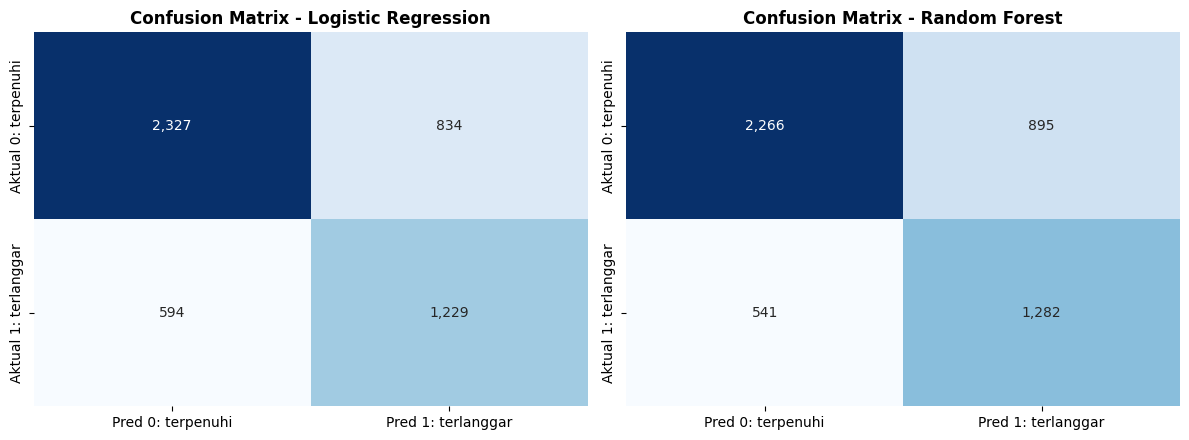

In [12]:
# Soal 2.4: Evaluasi model

# TODO:
# Evaluasi semua model yang Anda buat.
#
# CLASSIFICATION:
# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     confusion_matrix,
#     classification_report
# )
#
# REGRESSION:
# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_squared_error,
#     r2_score
# )
#
# Buat tabel perbandingan hasil agar mudah dianalisis.

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix)

hasil = []
for nama, model in semua_model.items():
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    proba_test = model.predict_proba(X_test)[:, 1]
    hasil.append({
        'Model': nama,
        'Accuracy (train)': accuracy_score(y_train, pred_train),
        'Accuracy (test)': accuracy_score(y_test, pred_test),
        'Balanced Acc (test)': balanced_accuracy_score(y_test, pred_test),
        'Precision (test)': precision_score(y_test, pred_test, zero_division=0),
        'Recall (test)': recall_score(y_test, pred_test),
        'F1 (train)': f1_score(y_train, pred_train),
        'F1 (test)': f1_score(y_test, pred_test),
        'ROC-AUC (test)': roc_auc_score(y_test, proba_test),
    })

tabel_hasil = pd.DataFrame(hasil).set_index('Model').round(3)
print('=== Perbandingan Model (kelas positif = SLA terlanggar) ===')
print(tabel_hasil.T.to_string())

# Confusion matrix untuk 2 model utama
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, nama in zip(axes, ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, semua_model[nama].predict(X_test))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0: terpenuhi', 'Pred 1: terlanggar'],
                yticklabels=['Aktual 0: terpenuhi', 'Aktual 1: terlanggar'])
    ax.set_title(f'Confusion Matrix - {nama}', fontweight='bold')
    tn, fp, fn, tp = cm.ravel()
    print(f'{nama}: TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}')
plt.tight_layout()
plt.show()

### Analisis Confusion Matrix — khusus Classification

Jika Anda mengerjakan classification, analisis confusion matrix untuk melihat jenis kesalahan model.

Untuk binary classification:

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

Untuk multiclass classification, confusion matrix akan memiliki lebih dari dua kelas.

**Jawaban:**
- **Kelas paling mudah dikenali:** SLA terpenuhi (kelas 0). Random Forest benar pada 2.266 dari 3.161 tiket (71,7%).
- **Kelas paling sering salah diprediksi:** SLA terlanggar (kelas 1). Sebanyak 541 dari 1.823 tiket (29,7%) tidak terdeteksi (false negative).
- **Yang lebih penting:** False negative, karena tiket berisiko yang tidak terdeteksi tidak mendapat perhatian lebih awal sehingga akhirnya melanggar SLA.
- **Konsekuensi:** False negative menyebabkan pelanggaran SLA dan ketidakpuasan pengguna. False positive (895 tiket) hanya membuat tim memprioritaskan tiket yang sebenarnya aman, sehingga dampaknya lebih ringan. Dibandingkan Logistic Regression (FN = 594), Random Forest menghasilkan 53 false negative lebih sedikit.


### Overfitting / Underfitting

Bandingkan performa pada data training dan testing.

Perhatikan:
- Apakah performa training jauh lebih baik daripada testing?
- Apakah model terlalu sederhana sehingga performanya rendah pada keduanya?
- Apakah terdapat indikasi overfitting atau underfitting?

Jelaskan berdasarkan hasil eksperimen, bukan hanya berdasarkan definisi teori.

**Perbandingan performa pada data training dan testing:**

| Model | Accuracy (train) | Accuracy (test) | Selisih | F1 (train) | F1 (test) | Selisih |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0,714 | 0,713 | 0,001 | 0,637 | 0,633 | 0,004 |
| Random Forest | 0,733 | 0,712 | 0,021 | 0,664 | 0,641 | 0,023 |

**Jawaban:**
- **Apakah training jauh lebih baik daripada testing?** Tidak. Selisihnya sangat kecil, hanya 0,001 untuk Logistic Regression dan sekitar 0,02 untuk Random Forest.
- **Apakah model terlalu sederhana?** Ada indikasi ringan. Performa kedua model sama-sama tertahan di sekitar 71% baik pada train maupun test, padahal Random Forest jauh lebih kompleks daripada Logistic Regression.
- **Kesimpulan:** Tidak ada indikasi overfitting, tetapi ada indikasi underfitting ringan. Penyebabnya kemungkinan bukan karena modelnya terlalu sederhana, melainkan karena informasi yang tersedia saat tiket dibuka memang terbatas untuk memprediksi kejadian selama tiket ditangani (misalnya reassignment atau menunggu respons pengguna).

### Feature Importance / Model Interpretation

Jika model Anda mendukung interpretasi fitur, analisis fitur yang paling berpengaruh.

Contoh:
- Random Forest → `feature_importances_`
- Linear/Logistic Regression → koefisien
- Model lain → gunakan metode interpretasi yang sesuai

> **Catatan:** Feature importance tidak otomatis berarti hubungan sebab-akibat.

Jika model tidak memiliki feature importance secara langsung, Anda dapat menggunakan permutation importance atau menjelaskan keterbatasan interpretasinya.


**Jawaban :** Metode Permutation Importance pada Random Forest (data test). Setiap fitur diacak satu per satu, lalu diukur seberapa besar balanced accuracy turun. Metode ini dipilih karena langsung menilai 11 fitur asli (bukan 318 kolom hasil one-hot) dan tidak bias terhadap fitur dengan banyak kategori.

| Peringkat | Fitur | Penurunan Balanced Accuracy |
|---:|---|---:|
| 1 | assignment_group | 0,0794 |
| 2 | category | 0,0232 |
| 3 | u_symptom | 0,0198 |
| 4 | subcategory | 0,0143 |
| 5 | location | 0,0112 |
| 6–11 | opened_hour, opened_dayofweek, priority, urgency, impact, contact_type | < 0,003 |

**Interpretasi:**
- **assignment_group paling berpengaruh**, jauh di atas fitur lain. Jika fitur ini diacak, balanced accuracy turun sekitar 8 poin (dari 0,710 menjadi sekitar 0,63). Artinya, tim yang menangani tiket adalah sinyal terkuat risiko pelanggaran SLA, kemungkinan karena perbedaan beban kerja, jenis masalah yang ditangani, atau kebutuhan eskalasi antar tim.
- **Jenis masalah** (category, u_symptom, subcategory) menjadi kelompok fitur berikutnya, yang masuk akal karena sebagian masalah memang lebih rumit dan lebih lama diselesaikan.
- **Priority ternyata hampir tidak berpengaruh** (0,0022), padahal di Challenge 1 pola per priority sangat kuat. Penyebabnya, 95% tiket berprioritas Moderate, sehingga priority hanya membantu membedakan sebagian kecil tiket.
- **Catatan:** Feature importance bukan hubungan sebab-akibat. Assignment group yang sering melanggar SLA belum tentu kinerjanya buruk; bisa jadi tim tersebut memang menangani masalah yang lebih sulit.

=== Permutation Importance (Random Forest, data test) ===
           fitur  penurunan_balanced_acc    std
assignment_group                  0.0794 0.0057
        category                  0.0232 0.0008
       u_symptom                  0.0198 0.0031
     subcategory                  0.0143 0.0045
        location                  0.0112 0.0029
     opened_hour                  0.0029 0.0014
opened_dayofweek                  0.0024 0.0014
        priority                  0.0022 0.0007
         urgency                  0.0021 0.0008
          impact                  0.0015 0.0011
    contact_type                  0.0004 0.0002


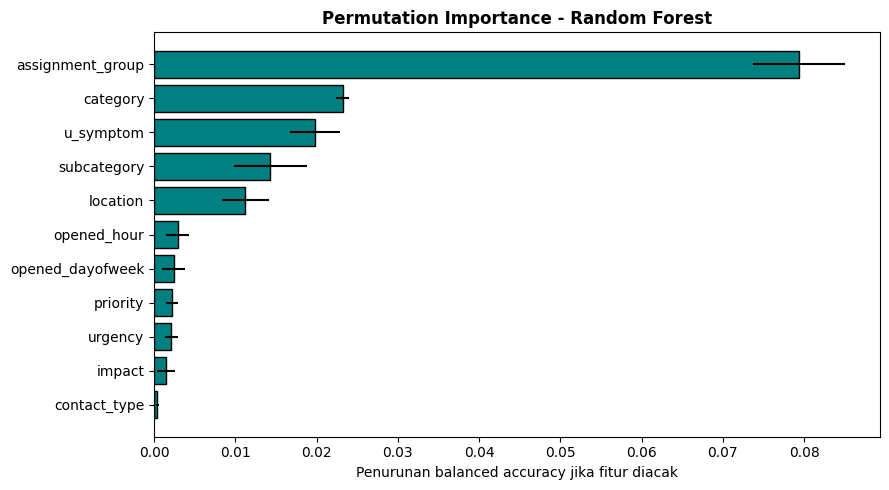

In [13]:
   # Feature Importance: Permutation Importance pada Random Forest
   from sklearn.inspection import permutation_importance

   perm = permutation_importance(model_alternatif, X_test, y_test,
                                 scoring='balanced_accuracy', n_repeats=5,
                                 random_state=RANDOM_STATE, n_jobs=-1)

   importance = (pd.DataFrame({'fitur': X_test.columns,
                               'penurunan_balanced_acc': perm.importances_mean,
                               'std': perm.importances_std})
                 .sort_values('penurunan_balanced_acc', ascending=False)
                 .round(4))
   print('=== Permutation Importance (Random Forest, data test) ===')
   print(importance.to_string(index=False))

   plt.figure(figsize=(9, 5))
   plt.barh(importance['fitur'], importance['penurunan_balanced_acc'],
            xerr=importance['std'], color='teal', edgecolor='black')
   plt.gca().invert_yaxis()
   plt.title('Permutation Importance - Random Forest', fontweight='bold')
   plt.xlabel('Penurunan balanced accuracy jika fitur diacak')
   plt.tight_layout()
   plt.show()

## 2.5 Memilih Model Final

Setelah membandingkan model, pilih **satu model final** untuk digunakan pada Challenge 3.

Pertimbangkan:
- Performa pada metrik utama
- Keseimbangan beberapa metrik
- Interpretabilitas
- Kompleksitas model
- Kecepatan
- Kebutuhan preprocessing
- Risiko overfitting
- Konteks penggunaan

**Model final yang saya pilih:** ``Random Forest``

**Alasan:**

Kedua model jauh lebih baik daripada Dummy Classifier (accuracy 63,4%) dan performanya hampir sama, dengan accuracy sekitar 71%. Random Forest dipilih karena unggul pada metrik utama, yaitu recall kelas "SLA terlanggar" (0,703 vs 0,674), sehingga mendeteksi 53 tiket berisiko lebih banyak daripada Logistic Regression. Random Forest juga sedikit lebih baik pada F1 (0,641) dan ROC-AUC (0,787), dengan selisih train–test yang kecil (0,021) sehingga tidak ada indikasi overfitting. Kekurangannya, Random Forest lebih sulit dijelaskan dan lebih lambat, sehingga Logistic Regression tetap menjadi alternatif yang layak jika interpretabilitas lebih diutamakan.

In [14]:


# Soal 2.5: Simpan model final
import joblib

model_final = model_alternatif  # Random Forest (sudah termasuk preprocessing dalam Pipeline)
joblib.dump(model_final, 'model.pkl')
print('✓ Model final (Random Forest) disimpan ke model.pkl')

# Cek: muat ulang dan pastikan hasilnya sama dengan model asli
model_cek = joblib.load('model.pkl')
sama = (model_cek.predict(X_test) == model_final.predict(X_test)).all()
print(f'✓ Model berhasil dimuat ulang, prediksi identik: {sama}')

✓ Model final (Random Forest) disimpan ke model.pkl
✓ Model berhasil dimuat ulang, prediksi identik: True



**Insight Challenge 2:**

1. **Jenis Masalah**: Target yang diprediksi adalah `sla_terlanggar` (1 = SLA terlanggar, 0 = SLA terpenuhi). Masalah ini termasuk binary classification karena targetnya hanya memiliki 2 kelas.

2. **Pemilihan Model**: Dibandingkan tiga model: Dummy Classifier sebagai batas bawah (selalu menebak kelas terbanyak), Logistic Regression sebagai baseline yang sederhana dan mudah dijelaskan, serta Random Forest sebagai alternatif yang mampu menangkap pola non-linear antar fitur kategori.

3. **Performa Model**: Logistic Regression dan Random Forest sama-sama jauh mengungguli Dummy (accuracy 63,4%), dengan accuracy sekitar 71%. Random Forest sedikit unggul pada recall (0,703 vs 0,674), F1 (0,641 vs 0,633), dan ROC-AUC (0,787 vs 0,780), sedangkan Logistic Regression sedikit unggul pada precision (0,596 vs 0,589).

4. **Kesalahan Model**: Pada Random Forest, 1.282 dari 1.823 tiket yang melanggar SLA berhasil terdeteksi, tetapi 541 tiket (29,7%) terlewat (false negative) dan 895 tiket aman salah ditandai berisiko (false positive). False negative lebih penting dalam use case ini karena tiket berisiko yang tidak terdeteksi berujung pada pelanggaran SLA.

5. **Overfitting/Underfitting**: Tidak ada indikasi overfitting karena selisih accuracy train–test sangat kecil (0,001 pada Logistic Regression dan 0,021 pada Random Forest). Terdapat underfitting ringan karena kedua model tertahan di sekitar 71%, kemungkinan karena informasi saat tiket dibuka masih terbatas.

6. **Feature Importance**: Fitur paling berpengaruh adalah assignment_group (penurunan balanced accuracy 0,079), diikuti category, u_symptom, dan subcategory. Priority hampir tidak berpengaruh karena 95% tiket berprioritas Moderate.

7. **Model Final**: Random Forest dipilih karena unggul pada recall sebagai metrik utama, sehingga mendeteksi 53 tiket berisiko lebih banyak dibanding Logistic Regression, tanpa indikasi overfitting.

8. **Langkah Improvement**: Menambahkan fitur beban kerja tim saat tiket dibuka (misalnya jumlah tiket aktif di assignment group tersebut), mencoba model boosting seperti HistGradientBoosting, melakukan tuning hyperparameter dengan cross-validation, dan menurunkan threshold prediksi agar recall kelas "SLA terlanggar" lebih tinggi.

---
<a id='challenge-3'></a>
## Challenge 3 - Prediction

**Tujuan:** Menggunakan model yang telah dilatih untuk memprediksi data baru yang belum pernah dilihat.

### Instruksi
- Muat kembali model yang sudah disimpan di Challenge 2
- Buat 2-3 contoh data baru dengan fitur yang sama dengan X
- Lakukan prediksi dan tampilkan hasilnya; jika model mendukung `predict_proba`, tampilkan probability/confidence scores                    **Interpretasi Hasil Prediksi:**
- **Tiket A** diprediksi SLA terpenuhi (25,5%) karena ditangani assignment group dan category dengan tingkat pelanggaran historis rendah.
- **Tiket B** diprediksi SLA terlanggar dengan keyakinan tinggi (92,7%) karena kombinasi assignment group dan category yang historisnya sering melanggar SLA, ditambah priority High.
- **Tiket C** diprediksi SLA terlanggar (59,9%) meskipun priority-nya Moderate, karena masuk via Email dan belum memiliki assignment group. Probabilitasnya mendekati batas 50%, sehingga prediksi ini kurang pasti.

In [15]:
# Soal 3.1: Muat model (jika perlu, jika di-run terpisah dari Challenge 2)

import joblib

model = joblib.load('model.pkl')
print('✓ Model loaded')

✓ Model loaded


In [16]:
# Soal 3.2: Buat data baru untuk diprediksi
# Nilai kategori diambil dari dataset (karena dianonimkan), dipilih berdasarkan
# tingkat pelanggaran SLA historis (minimal 100 tiket agar angkanya bisa dipercaya)

def tingkat_pelanggaran(kolom, min_tiket=100):
    tabel = df.groupby(kolom)['sla_terlanggar'].agg(['mean', 'size'])
    return tabel[tabel['size'] >= min_tiket].sort_values('mean')

def paling_umum(kolom, kategori=None):
    data = df if kategori is None else df[df['category'] == kategori]
    return data[kolom].mode()[0]

grup = tingkat_pelanggaran('assignment_group')
kategori = tingkat_pelanggaran('category')
grup_aman, grup_berisiko = grup.index[0], grup.index[-1]
kategori_aman, kategori_berisiko = kategori.index[0], kategori.index[-1]
kategori_umum = paling_umum('category')

# Kombinasi impact & urgency yang paling sering menghasilkan priority High di data
impact_high, urgency_high = (df[df['priority'] == '2 - High'][['impact', 'urgency']]
                             .value_counts().index[0])

print('Assignment group paling aman    :', grup_aman, f"({grup.loc[grup_aman, 'mean']:.1%} melanggar SLA)")
print('Assignment group paling berisiko:', grup_berisiko, f"({grup.loc[grup_berisiko, 'mean']:.1%} melanggar SLA)")
print('Category paling aman            :', kategori_aman, f"({kategori.loc[kategori_aman, 'mean']:.1%})")
print('Category paling berisiko        :', kategori_berisiko, f"({kategori.loc[kategori_berisiko, 'mean']:.1%})")

data_baru = pd.DataFrame({
    'contact_type':     ['Phone', 'Phone', 'Email'],
    'location':         [paling_umum('location')] * 3,
    'category':         [kategori_aman, kategori_berisiko, kategori_umum],
    'subcategory':      [paling_umum('subcategory', kategori_aman),
                         paling_umum('subcategory', kategori_berisiko),
                         paling_umum('subcategory', kategori_umum)],
    'u_symptom':        [paling_umum('u_symptom', kategori_aman),
                         paling_umum('u_symptom', kategori_berisiko),
                         np.nan],
    'impact':           ['2 - Medium', impact_high, '2 - Medium'],
    'urgency':          ['2 - Medium', urgency_high, '2 - Medium'],
    'priority':         ['3 - Moderate', '2 - High', '3 - Moderate'],
    'assignment_group': [grup_aman, grup_berisiko, np.nan],
    'opened_hour':      [10, 22, 14],   # jam 10 pagi, 10 malam, 2 siang
    'opened_dayofweek': [1, 4, 2],      # Selasa, Jumat, Rabu
}, index=['Tiket A: rutin', 'Tiket B: berisiko', 'Tiket C: email, belum di-assign'])

data_baru = data_baru[X.columns]  # pastikan urutan kolom sama dengan X

print('\nData baru untuk diprediksi:')
print(data_baru.T.to_string())

Assignment group paling aman    : Group 64 (11.4% melanggar SLA)
Assignment group paling berisiko: Group 9 (88.1% melanggar SLA)
Category paling aman            : Category 35 (8.2%)
Category paling berisiko        : Category 45 (76.5%)

Data baru untuk diprediksi:
                  Tiket A: rutin Tiket B: berisiko Tiket C: email, belum di-assign
contact_type               Phone             Phone                           Email
location            Location 204      Location 204                    Location 204
category             Category 35       Category 45                     Category 42
subcategory       Subcategory 28   Subcategory 200                 Subcategory 223
u_symptom            Symptom 506       Symptom 208                             NaN
impact                2 - Medium        2 - Medium                      2 - Medium
urgency               2 - Medium          1 - High                      2 - Medium
priority            3 - Moderate          2 - High                    3

In [17]:
# Soal 3.3: Lakukan prediksi dan tampilkan hasil

hasil_prediksi = model.predict(data_baru)
probabilitas = model.predict_proba(data_baru)[:, 1]

hasil = pd.DataFrame({
    'Prediksi': np.where(hasil_prediksi == 1, 'SLA terlanggar', 'SLA terpenuhi'),
    'Probabilitas SLA terlanggar': [f'{p:.1%}' for p in probabilitas],
}, index=data_baru.index)

print(f'Hasil Prediksi: {hasil_prediksi}\n')
print(hasil.to_string())

Hasil Prediksi: [0 1 1]

                                       Prediksi Probabilitas SLA terlanggar
Tiket A: rutin                    SLA terpenuhi                       25.5%
Tiket B: berisiko                SLA terlanggar                       92.7%
Tiket C: email, belum di-assign  SLA terlanggar                       59.9%


---
<a id='challenge-4'></a>
## Challenge 4 - Integrasi Gemini API

**Tujuan:** Menggunakan Gemini API untuk menjelaskan hasil prediksi dengan bahasa natural yang mudah dipahami.
- Install Google AI library: `pip install google-generativeai python-dotenv`

In [19]:
# Soal 4.1: Setup Gemini API
!pip install -q google-genai

import time
from google import genai
from google.colab import userdata

# Daftar model dicoba berurutan. Jika satu sibuk (503) atau tidak tersedia (404),
# otomatis pindah ke model berikutnya.
DAFTAR_MODEL = ['gemini-3.8-flash', 'gemini-3.6-flash', 'gemini-3.5-flash-lite', 'gemini-3.1-flash-lite']
MODEL_TERPAKAI = None

API_KEY = userdata.get('GEMINI_API_KEY')
client = genai.Client(api_key=API_KEY)

def tanya_gemini(prompt, percobaan_per_model=2):
    """Kirim prompt ke Gemini dengan retry dan fallback ke model cadangan."""
    global MODEL_TERPAKAI
    for model in DAFTAR_MODEL:
        for i in range(1, percobaan_per_model + 1):
            try:
                teks = client.models.generate_content(model=model, contents=prompt).text
                MODEL_TERPAKAI = model
                return teks
            except Exception as e:
                pesan = str(e)
                if '503' in pesan or '429' in pesan:
                    print(f'{model}: server sibuk (percobaan {i}/{percobaan_per_model})')
                    time.sleep(10)
                elif '404' in pesan:
                    print(f'{model}: tidak tersedia untuk API key ini, lanjut ke model berikutnya')
                    break
                else:
                    raise
    raise RuntimeError('Semua model sedang sibuk atau tidak tersedia. Coba lagi nanti.')

try:
    print('Tes koneksi:', tanya_gemini('Balas hanya dengan kata: OK').strip())
    print(f'✓ Gemini API configured successfully (model: {MODEL_TERPAKAI})')
except Exception as e:
    print(f'⚠️ ERROR: {e}')

gemini-3.8-flash: server sibuk (percobaan 1/2)
gemini-3.8-flash: server sibuk (percobaan 2/2)
Tes koneksi: OK
✓ Gemini API configured successfully (model: gemini-3.6-flash)


Model gemini-3.8-flash sedang mengalami beban tinggi (error 503), sehingga digunakan model cadangan (model: gemini-3.6-flash)

In [20]:
## Soal 4.2: Susun prompt dan minta penjelasan dari Gemini
# (Membutuhkan fungsi tanya_gemini dari Soal 4.1, jadi jalankan Soal 4.1 terlebih dahulu)

# Fakta historis dari dataset, supaya Gemini menjelaskan berdasarkan data (bukan mengarang)
persen_email = df.loc[df['contact_type'] == 'Email', 'sla_terlanggar'].mean()
persen_tanpa_grup = df.loc[df['assignment_group'].isna(), 'sla_terlanggar'].mean()
persen_rata2 = df['sla_terlanggar'].mean()

fakta_historis = f"""
- Rata-rata seluruh tiket: {persen_rata2:.1%} melanggar SLA
- Assignment group {grup_aman}: {grup.loc[grup_aman, 'mean']:.1%} tiketnya melanggar SLA
- Assignment group {grup_berisiko}: {grup.loc[grup_berisiko, 'mean']:.1%} tiketnya melanggar SLA
- {kategori_aman}: {kategori.loc[kategori_aman, 'mean']:.1%} tiketnya melanggar SLA
- {kategori_berisiko}: {kategori.loc[kategori_berisiko, 'mean']:.1%} tiketnya melanggar SLA
- Tiket via Email: {persen_email:.1%} melanggar SLA
- Tiket yang belum memiliki assignment group saat dibuka: {persen_tanpa_grup:.1%} melanggar SLA
"""

prompt = f"""
Kamu adalah analis IT Service Management yang menjelaskan hasil model machine learning
kepada manajer service desk yang tidak memiliki latar belakang teknis.

KONTEKS:
Model Random Forest memprediksi apakah tiket insiden IT akan MELANGGAR SLA,
menggunakan informasi yang tersedia saat tiket pertama kali dibuka.
Data berasal dari sistem ServiceNow; nama group, category, dan lokasi sudah dianonimkan.
Performa model pada data uji: accuracy 71%, recall 70% (70% tiket yang melanggar SLA berhasil
terdeteksi), precision 59% (59% tiket yang ditandai berisiko memang melanggar SLA).
Fitur paling berpengaruh: assignment_group, lalu category, u_symptom, dan subcategory.

PENJELASAN FITUR:
- contact_type: saluran masuk tiket (Phone, Email, Self service)
- category, subcategory, u_symptom: jenis masalah yang dilaporkan
- impact, urgency, priority: tingkat dampak, urgensi, dan prioritas tiket
- assignment_group: tim yang menangani tiket (NaN = belum ditugaskan)
- opened_hour, opened_dayofweek: jam dan hari tiket dibuka (0 = Senin)

DATA TIKET BARU:
{data_baru.T.to_string()}

HASIL PREDIKSI MODEL:
{hasil.to_string()}

FAKTA HISTORIS DARI DATA:
{fakta_historis}

TUGAS:
Untuk setiap tiket, jelaskan dalam 2-3 kalimat mengapa model memberikan prediksi tersebut,
dengan merujuk pada fakta historis di atas. Lalu berikan satu rekomendasi tindakan praktis
untuk tim service desk. Tutup dengan 1-2 kalimat tentang keterbatasan prediksi ini.

ATURAN:
- Gunakan bahasa Indonesia yang mudah dipahami, maksimal 300 kata.
- Gunakan HANYA fakta yang diberikan di atas; jangan mengarang angka atau informasi lain.
- Jangan menyatakan hubungan sebab-akibat; gunakan kata seperti "berkaitan dengan" atau "historisnya".
- Jangan menyalahkan atau menilai kinerja tim tertentu.
- Tegaskan bahwa probabilitas adalah perkiraan model, bukan kepastian.
"""

try:
    penjelasan = tanya_gemini(prompt)
    print('=== Penjelasan dari Gemini ===\n')
    print(penjelasan)
    print('\n---\nCatatan: Penjelasan di atas dihasilkan oleh AI (Gemini) berdasarkan output model '
          'dan perlu ditinjau oleh manusia sebelum digunakan.')
except Exception as e:
    print(f'Error: {e}')

gemini-3.8-flash: server sibuk (percobaan 1/2)
=== Penjelasan dari Gemini ===

Berikut adalah penjelasan hasil prediksi model machine learning untuk tiga tiket baru:

* **Tiket A (Prediksi: SLA Terpenuhi, Estimasi Risiko: 25.5%)**  
  Model memperkirakan tiket ini berisiko rendah karena ditangani oleh Group 64, yang historisnya mencatat 11.4% pelanggaran SLA. Selain itu, masalahnya masuk dalam Category 35 yang secara historis hanya memiliki 8.2% tingkat pelanggaran SLA, jauh di bawah rata-rata keseluruhan tiket (36.6%).

* **Tiket B (Prediksi: SLA Terlanggar, Estimasi Risiko: 92.7%)**  
  Tiket ini diperkirakan berisiko tinggi karena ditujukan ke Group 9, di mana historisnya 88.1% tiket terkait kelompok ini melanggar SLA. Karakteristik masalah pada Category 45 juga historisnya berkaitan dengan 76.5% tiket yang melanggar SLA.

* **Tiket C (Prediksi: SLA Terlanggar, Estimasi Risiko: 59.9%)**  
  Model menandai tiket ini berisiko karena dikirim melalui saluran Email, yang secara historis 

**Catatan Challenge 4:**
- **Model dan library:** Menggunakan library `google-genai` dengan model utama `gemini-3.8-flash` dan model cadangan `gemini-3.6-flash`, karena library `google-generativeai` dan model `gemini-pro` di template sudah tidak tersedia. Saat tes koneksi (Soal 4.1), `gemini-3.8-flash` sedang sibuk sehingga dijawab oleh `gemini-3.6-flash`, sedangkan penjelasan pada Soal 4.2 berhasil dijawab oleh `gemini-3.8-flash`. API key disimpan di Colab Secrets.
- **Kendala:** Server Gemini sempat sibuk (error 503 UNAVAILABLE), sehingga ditambahkan mekanisme *retry* otomatis dan model cadangan.
- **Desain prompt:** Prompt berisi konteks, penjelasan fitur, hasil prediksi, fakta historis dari data, serta aturan agar Gemini tidak mengarang angka, tidak menyatakan sebab-akibat, dan tidak menyalahkan tim tertentu.
- **Evaluasi output:** Gemini mematuhi aturan utama: semua angka sesuai fakta historis dan interpretasi precision sudah tepat. Kekurangannya, Gemini tidak memberi rekomendasi untuk Tiket A dan tidak menyebutkan bahwa sekitar 30% tiket yang benar-benar melanggar SLA bisa tidak terdeteksi (recall 70%).
- **Transparansi:** Output diberi catatan bahwa penjelasan dihasilkan oleh AI dan perlu ditinjau manusia sebelum digunakan.

---
<a id='challenge-5'></a>
## Challenge 5 - Responsible AI Reflection

**Tujuan:** Merefleksikan aspek etika dan tanggung jawab dalam penggunaan AI/ML.

### Instruksi
Jawab SEMUA pertanyaan reflektif berikut dalam sel markdown di bawah. Setiap jawaban minimal 3-5 kalimat, gunakan format yang rapi (bullet points, paragraf, dll).

**Jawaban Reflection (Jawab semua 5 pertanyaan):**

### 1. Bias Data
**Pertanyaan:** Apakah dataset yang digunakan berpotensi bias? Apakah data representatif untuk semua kelompok demografis (gender, usia, etnis, lokasi, dll)? Jelaskan konsekuensi jika ada bias.

**Jawaban:**
Dataset tidak memuat data demografis pengguna, dan seluruh nama group, kategori, serta lokasi sudah dianonimkan, sehingga risiko bias demografis langsung relatif kecil. Namun, data hanya berasal dari satu perusahaan dan satu instance ServiceNow, sehingga belum tentu mewakili organisasi lain. Distribusi datanya juga sangat timpang: 95% tiket berprioritas Moderate dan 99% masuk via Phone, sehingga model kurang andal untuk tiket High/Critical maupun tiket via Email dan Self service. Konsekuensinya, model dapat memberi prediksi yang kurang akurat untuk kelompok tiket yang jarang muncul, dan dapat memperkuat label "berisiko" pada tim tertentu hanya berdasarkan pola historis.

---

### 2. Keterbatasan Model
**Pertanyaan:** Dalam kondisi apa model ini bisa memberikan prediksi yang salah atau menyesatkan? Apakah ada edge cases atau input yang tidak valid?

**Jawaban:**
Model hanya menggunakan informasi saat tiket dibuka, sehingga tidak mengetahui kejadian setelahnya seperti reassignment, menunggu respons pengguna, atau eskalasi ke vendor. Dengan recall 70%, sekitar 30% tiket yang benar-benar melanggar SLA tidak terdeteksi. Model juga kurang andal untuk assignment group atau kategori baru yang belum pernah muncul di data training, serta untuk prediksi dengan probabilitas mendekati 50% seperti Tiket C (59,9%). Selain itu, data berasal dari tahun 2016, sehingga perubahan proses, struktur tim, atau definisi SLA dapat membuat pola yang dipelajari model tidak lagi berlaku.

---

### 3. Transparansi AI Generatif
**Pertanyaan:** Penjelasan di Challenge 4 dihasilkan oleh AI (Gemini). Apakah pengguna akhir PERLU TAHU bahwa penjelasan ini dari AI? Apa risikonya jika tidak transparansi?

**Jawaban:**
Ya, pengguna perlu tahu bahwa penjelasan tersebut dihasilkan oleh AI. Tanpa transparansi, pengguna dapat menganggap penjelasan Gemini sebagai analisis pasti dari ahli, padahal AI generatif bisa salah, menghilangkan informasi penting, atau mengarang fakta. Hal ini terbukti pada Challenge 4: meskipun semua angka yang disebutkan Gemini sudah benar, Gemini tidak menyebutkan bahwa sekitar 30% tiket berisiko bisa tidak terdeteksi. Karena itu, setiap output diberi catatan bahwa penjelasan dihasilkan oleh AI dan perlu ditinjau manusia sebelum digunakan untuk mengambil keputusan.

---

### 4. Dampak Sosial
**Pertanyaan:** Jika model ini digunakan dalam skala besar/nyata (misalnya di aplikasi mobile, rumah sakit, atau perusahaan), dampak apa yang mungkin timbul (positif & negatif)? Siapa saja yang bisa terpengaruh?

**Jawaban:**
Dampak positifnya, tim service desk dapat memprioritaskan tiket berisiko sejak awal, sehingga pelanggaran SLA berkurang dan kepuasan pengguna meningkat. Dampak negatifnya, model dapat disalahgunakan untuk menilai kinerja tim, misalnya Group 9 yang 88,1% tiketnya historis melanggar SLA, padahal tim tersebut mungkin menangani masalah yang lebih sulit. Tiket yang diprediksi aman juga berisiko diabaikan, padahal sebagian di antaranya sebenarnya melanggar SLA, dan banyaknya false positive (895 tiket) dapat menyebabkan kelelahan akibat terlalu banyak peringatan. Pihak yang terpengaruh meliputi analis service desk, tim resolver, manajemen IT, dan pengguna akhir yang menunggu tiketnya diselesaikan.

---

### 5. Rekomendasi Responsible AI
**Pertanyaan:** Apa langkah/strategi yang bisa diambil untuk membuat sistem ini lebih bertanggung jawab (responsible AI)? Pikir tentang: transparency, fairness, accountability, security, dll.

**Jawaban:**
- **Transparency:** Menampilkan probabilitas beserta faktor utama di balik prediksi, serta label bahwa penjelasan dihasilkan oleh AI.
- **Fairness:** Tidak menggunakan model untuk menilai kinerja tim atau individu, dan memantau performa model secara terpisah per priority, contact type, dan assignment group.
- **Accountability:** Model hanya menjadi alat bantu prioritisasi, sedangkan keputusan akhir tetap berada di tangan team lead atau analis (*human-in-the-loop*).
- **Security & Privacy:** Menjaga data tetap teranonimkan, menyimpan API key di tempat aman, dan tidak mengirim data pribadi pengguna ke layanan AI eksternal.
- **Monitoring:** Mengevaluasi dan melatih ulang model secara berkala agar tetap relevan dengan perubahan proses dan struktur tim.
---

---
## Kesimpulan Akhir

**Ringkasan Pengerjaan:**

- **Yang dipelajari:** Project ini membangun model *early warning* untuk memprediksi pelanggaran SLA tiket insiden IT (Layanan IT Support) menggunakan data nyata ServiceNow, melalui alur lengkap dari eksplorasi data, machine learning, prediksi, integrasi Gemini, hingga refleksi Responsible AI. Saya belajar bahwa data perlu disiapkan sesuai tujuan, yaitu meringkas 141.712 event menjadi 24.918 insiden dan hanya memakai informasi yang tersedia saat tiket dibuka. Saya juga belajar bahwa evaluasi model tidak cukup dengan accuracy, tetapi perlu dibandingkan dengan baseline dan dilihat dari recall serta confusion matrix.

- **Kendala dan solusinya:** Template notebook dirancang untuk laptop, sehingga path file, dotenv, dan library Gemini lama perlu disesuaikan agar berjalan di Google Colab. Saya juga harus berhati-hati terhadap data leakage, misalnya membuang kolom durasi penyelesaian dari fitur karena nilainya baru diketahui setelah tiket selesai. Saat integrasi Gemini, server sempat sibuk (error 503), sehingga saya menambahkan mekanisme *retry* otomatis dan model cadangan.

- **Insight utama ("aha moment"):** Accuracy 71% baru bermakna setelah dibandingkan dengan Dummy Classifier yang sudah mencapai 63,4% hanya dengan menebak "SLA terpenuhi". Hal yang paling mengejutkan adalah priority terlihat sangat berpengaruh di eksplorasi data, tetapi hampir tidak berpengaruh di model karena 95% tiket berprioritas Moderate, sedangkan fitur terpenting justru assignment group.

- **Yang ingin dipelajari lebih lanjut:** Saya ingin meningkatkan model dengan fitur beban kerja tim, model boosting, dan pengaturan threshold untuk menaikkan recall. Selain itu, saya ingin mempelajari cara men-deploy model ini sebagai API di cloud agar dapat terintegrasi langsung dengan sistem ticketing.